In [1]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Finding the Hidden Pulse

## Mathematical Detection of Natural Video Cut Points in Music

*Math Concepts for Developers — Final Project*

## 1. Introduction

As a creator of music videos, my work often requires choosing cut points that feel natural with the rhythm and structure of the music.

In music with strong transients, such as pronounced drum hits or sharp attacks, where the pacing is driven by high energy, suitable cut points may be relatively easy to identify. In smoother musical passages, however, natural editing points may follow a less obvious periodic pulse that is not represented by a single strong sound event.

My last project was of that kind. A symphony from 5 parts. I spent days getting through the first half of a part IV, cutting again and again and replaying tiny fragments many times to find the right editing points. In the middle of the song, I realized that several consecutive clips had almost the same duration: 2 seconds and 20 frames (02:20 at 24 fps, approximately 2.83 s).

I decided to test this observation. I cut the next clip to the same duration without listening for a strong hit, without looking at the waveform, and without searching for an obvious peak. It fit naturally. I continued using the same interval and finished almost the entire second half of the video in about two hours, using this interval almost all the time, with few exceptions.

With this project, I will investigate whether simple mathematical analysis of an audio signal can detect these underlying rhythmic patterns and identify useful candidate points for video editing, potentially saving significant editing time and nerves.

### Research Question

Can a general mathematical method detect candidate cut points that align with manually selected edits across both strongly percussive and smooth musical passages?

### Project Scope

The project focuses on mathematical signal analysis.

The initial approach will examine:
- changes in local signal energy;
- repeated temporal patterns;
- periodicity in the audio signal;
- candidate cut points derived from these patterns.

The detected points will later be compared with manually selected edit points from real video projects.

## 2. Data and First Observation

The first experiment uses the track in which the original editing problem was observed.

During manual editing at 24 fps, several consecutive video clips naturally converged to a duration of 2 seconds and 20 frames:

\[
2 + \frac{20}{24} \approx 2.83 \text{ seconds}
\]

This observation suggests that the music may contain an underlying periodic structure near this interval.

The first goal is to inspect the audio signal and determine whether such a periodic pattern can be detected mathematically.

In [2]:
audio_path = Path("data/earth.wav")

if not audio_path.exists():
    raise FileNotFoundError(
        f"Audio file not found: {audio_path.resolve()}"
    )

sample_rate, audio = wavfile.read(audio_path)

print("Sample rate:", sample_rate)
print("Shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")

Sample rate: 48000
Shape: (12432043, 2)
Duration: 259.00089583333335 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_67064\478631362.py:8: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read(audio_path)


### 2.1 Representing the Audio Signal

Sound can be represented mathematically as an amplitude function of time:

$$
x(t)
$$

The WAV file is a sampled digital representation of this signal. With a sampling rate of

$$
f_s = 48000 \text{ Hz},
$$

the signal is represented by 48,000 measured amplitude values per second.

For sample index \(n\), the corresponding time is

$$
t_n = \frac{n}{f_s}.
$$

Therefore, the values stored in Python can be interpreted as samples of the underlying function:

$$
x(t_n).
$$

The WAV file contains two channels (stereo). For the initial analysis, the two channels are combined by taking their average, producing one amplitude value for each sampled point in time.

In [3]:
# Combine the stereo channels into one signal
audio_mono = audio.mean(axis=1).astype(np.float64)

# Normalize the amplitude to the interval [-1, 1]
x = audio_mono / np.max(np.abs(audio_mono))

# Create the corresponding time values
t = np.arange(len(x)) / sample_rate

print(f"Number of samples: {len(x)}")
print(f"Sampling rate: {sample_rate} Hz")
print(f"Duration: {t[-1]:.2f} seconds")

Number of samples: 12432043
Sampling rate: 48000 Hz
Duration: 259.00 seconds


### 2.2 Visualizing the Signal

The audio can now be viewed as an amplitude function of time:

$$
x(t).
$$

The complete recording contains more than twelve million samples. Plotting every sample is unnecessary for an overview, so a reduced number of points is used only for visualization. The original signal remains unchanged for the mathematical analysis.

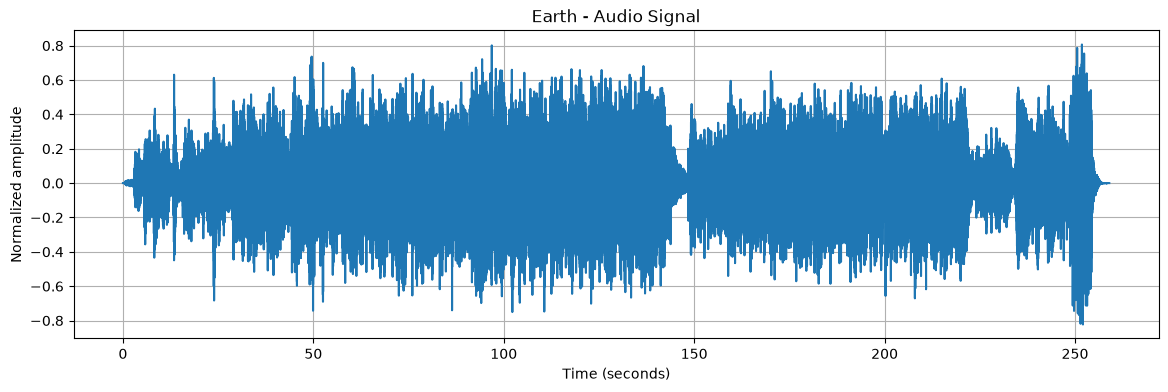

In [4]:
# Use fewer points only for plotting
target_points = 100_000
step = max(1, len(x) // target_points)

plt.figure(figsize=(14, 4))
plt.plot(t[::step], x[::step])

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Earth - Audio Signal")
plt.grid()

plt.show()

### 2.3 Local Mean-Square Signal Level

The raw audio function \(x(t)\) changes too rapidly to reveal the slower rhythmic structure directly.

A simple way to describe the local strength of the signal is to square its amplitude:

$$
x^2(t).
$$

Squaring has two useful effects:

- positive and negative amplitudes no longer cancel each other;
- larger amplitudes contribute more strongly.

The signal is then divided into short time intervals. For each interval, the average squared amplitude is calculated:

$$
E_i =
\frac{1}{N}
\sum_{k=0}^{N-1} x^2_{iN+k},
$$

where \(N\) is the number of audio samples in one time window.

This produces a new, much slower function \(E(t)\), which represents the local mean-square signal level over time.

In [5]:
# Duration of one analysis window
window_seconds = 0.05

# Number of audio samples in one window
window_size = int(window_seconds * sample_rate)

# Keep only the part that fits into complete windows
usable_samples = (len(x) // window_size) * window_size
x_trimmed = x[:usable_samples]

# Split the signal into equal time windows
windows = x_trimmed.reshape(-1, window_size)

# Mean squared amplitude in every window
local_energy = np.mean(windows ** 2, axis=1)

# Time position of every energy value
energy_time = np.arange(len(local_energy)) * window_seconds

print("Window duration:", window_seconds, "seconds")
print("Samples per window:", window_size)
print("Number of energy values:", len(local_energy))

Window duration: 0.05 seconds
Samples per window: 2400
Number of energy values: 5180


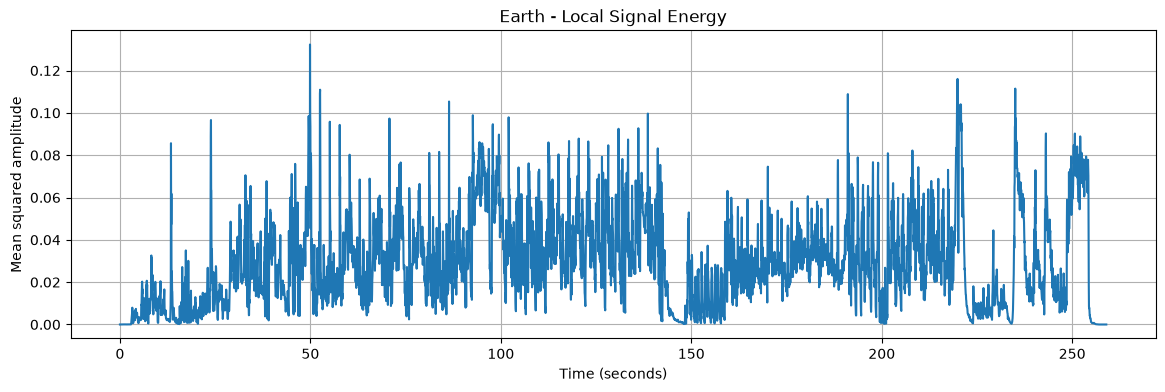

In [6]:
plt.figure(figsize=(14, 4))
plt.plot(energy_time, local_energy)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean squared amplitude")
plt.title("Earth - Local Signal Energy")
plt.grid()

plt.show()

### 2.4 Rate of Change

The local mean-square signal level changes over time. To measure how quickly it changes, a numerical approximation of the first derivative can be used.

For consecutive values separated by a time interval \(\Delta t\):

$$
E'(t) \approx \frac{E(t + \Delta t) - E(t)}{\Delta t}.
$$

Large positive values indicate a rapid increase in signal level, while large negative values indicate a rapid decrease.

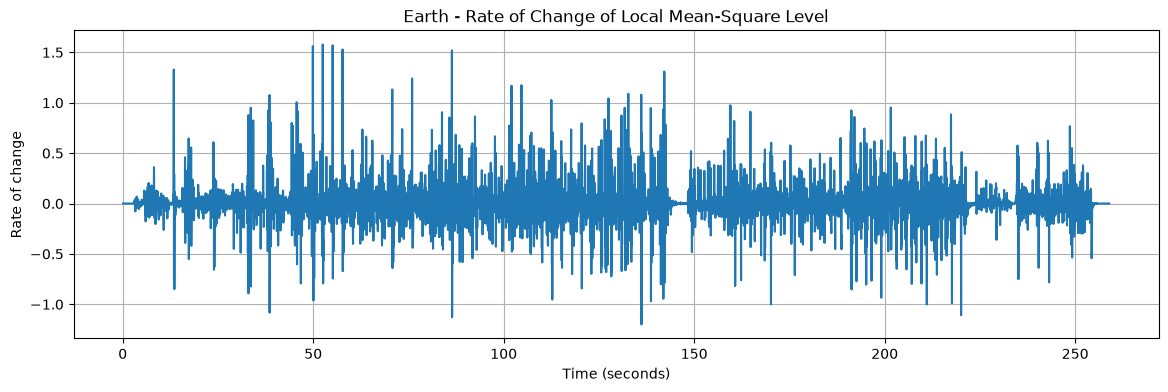

In [7]:
# Numerical approximation of the first derivative
energy_change = np.diff(local_energy) / window_seconds

# Corresponding time values
change_time = energy_time[1:]

plt.figure(figsize=(14, 4))
plt.plot(change_time, energy_change)

plt.xlabel("Time (seconds)")
plt.ylabel("Rate of change")
plt.title("Earth - Rate of Change of Local Mean-Square Level")
plt.grid()

plt.show()

#### Observation

The first derivative highlights rapid changes in the local signal level, producing clear positive and negative peaks.

However, the result contains many short-term changes and does not directly reveal the slower periodic pattern observed during manual editing.

This suggests that rate of change may be useful for detecting strong musical events(usefull for part III - Fire, but not for part IV - Earth), but a different method is needed to investigate repeated timing patterns.

### 2.5 Searching for Periodicity

A repeated rhythmic structure should produce similar signal patterns at regular time intervals.

To test this, the local signal-level function can be compared with a shifted copy of itself.

For two vectors, similarity can be measured using the dot product. If the signal resembles itself after a time shift \(\tau\), the similarity should increase for that shift.

The goal is to test different time shifts and determine whether some intervals produce consistently higher similarity.

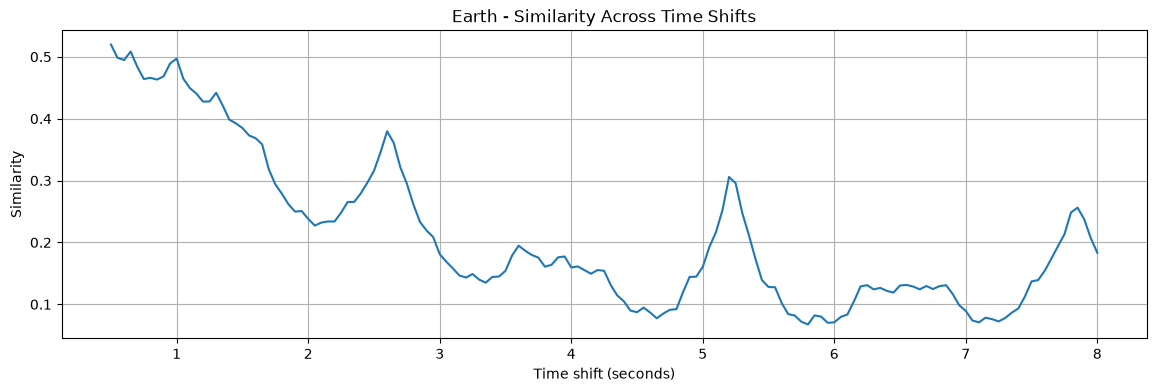

In [8]:
# Remove the average level so that we compare variations around the mean
energy_centered = local_energy - np.mean(local_energy)

# Test time shifts from 0.5 to 8 seconds
min_lag_seconds = 0.5
max_lag_seconds = 8.0

min_lag = int(min_lag_seconds / window_seconds)
max_lag = int(max_lag_seconds / window_seconds)

lags = np.arange(min_lag, max_lag + 1)
similarities = []

for lag in lags:
    a = energy_centered[:-lag]
    b = energy_centered[lag:]

    similarity = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    similarities.append(similarity)

lag_times = lags * window_seconds
similarities = np.array(similarities)

plt.figure(figsize=(14, 4))
plt.plot(lag_times, similarities)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Earth - Similarity Across Time Shifts")
plt.grid()

plt.show()

#### Observation

The similarity curve shows a strong expected value for very small time shifts, since nearby parts of the signal naturally resemble each other.

More importantly, the graph contains clear local maxima around approximately **2.6 s**, **5.2 s**, and **7.8 s**. These values are close to multiples of a common interval.

This suggests that the audio signal may contain a repeated temporal structure with an underlying period of approximately **2.6 seconds**.


The detected period of 2.60 s differs from my initial manual observation of 2.83 s.

However, the practical validation will show whether the mathematically detected period provides useful editing points.

### 2.6 Detecting Candidate Periods

The previous graph suggests several repeated similarity peaks, but visual inspection alone is not sufficient.

A simple local maximum can be defined as a point whose value is greater than the values immediately before and after it:

$$
S_i > S_{i-1}
\quad \text{and} \quad
S_i \geq S_{i+1}.
$$

Very small time shifts are excluded from this step because nearby parts of a continuous audio signal naturally resemble each other.

The remaining local maxima are treated as candidate repetition periods and ranked by similarity.

In [9]:
# Ignore very small shifts where similarity is naturally high
candidate_min_seconds = 1.5

candidate_indices = []

for i in range(1, len(similarities) - 1):
    is_local_maximum = (
        similarities[i] > similarities[i - 1]
        and similarities[i] >= similarities[i + 1]
    )

    is_long_enough = lag_times[i] >= candidate_min_seconds

    if is_local_maximum and is_long_enough:
        candidate_indices.append(i)

candidate_indices = np.array(candidate_indices)

# Rank the local maxima by similarity
sorted_indices = candidate_indices[
    np.argsort(similarities[candidate_indices])[::-1]
]

top_candidates = sorted_indices[:8]

print("Top candidate periods:")

for i in top_candidates:
    print(
        f"{lag_times[i]:.2f} s "
        f"(similarity = {similarities[i]:.3f})"
    )

Top candidate periods:
2.60 s (similarity = 0.380)
5.20 s (similarity = 0.306)
7.85 s (similarity = 0.256)
1.95 s (similarity = 0.251)
2.15 s (similarity = 0.234)
3.60 s (similarity = 0.195)
3.95 s (similarity = 0.177)
4.05 s (similarity = 0.161)


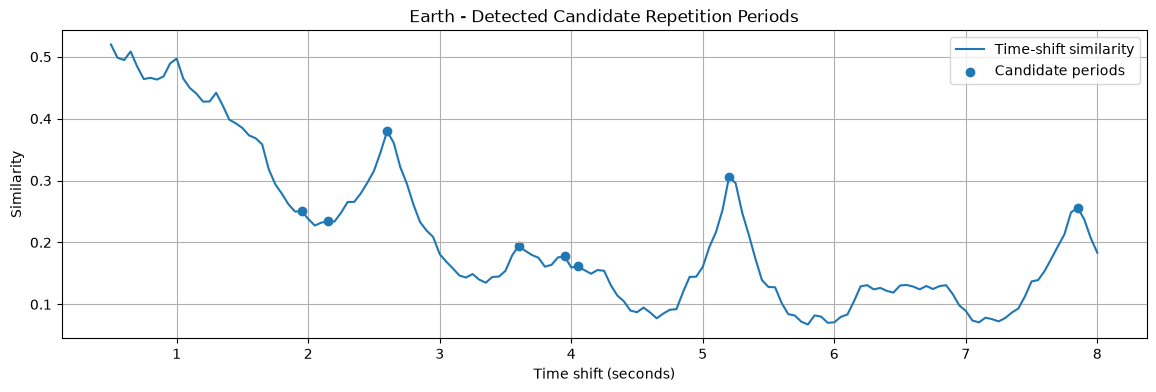

In [10]:
plt.figure(figsize=(14, 4))

plt.plot(
    lag_times,
    similarities,
    label="Time-shift similarity"
)

plt.scatter(
    lag_times[top_candidates],
    similarities[top_candidates],
    label="Candidate periods"
)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Earth - Detected Candidate Repetition Periods")
plt.grid()
plt.legend()

plt.show()

### 2.7 Locating the Repeated Pattern in Time

The detected period describes the distance between repeated patterns, but it does not specify where those patterns occur in the song.

To obtain candidate editing times, the signal can be divided into cycles using the strongest detected period.

Values that occupy the same relative position inside each cycle are then averaged. If a particular position repeatedly contains a similar signal feature, it should become visible in this average cycle.

This allows the period \(T\) to be combined with a phase offset \(t_0\), producing candidate times:

$$
t_k = t_0 + kT.
$$

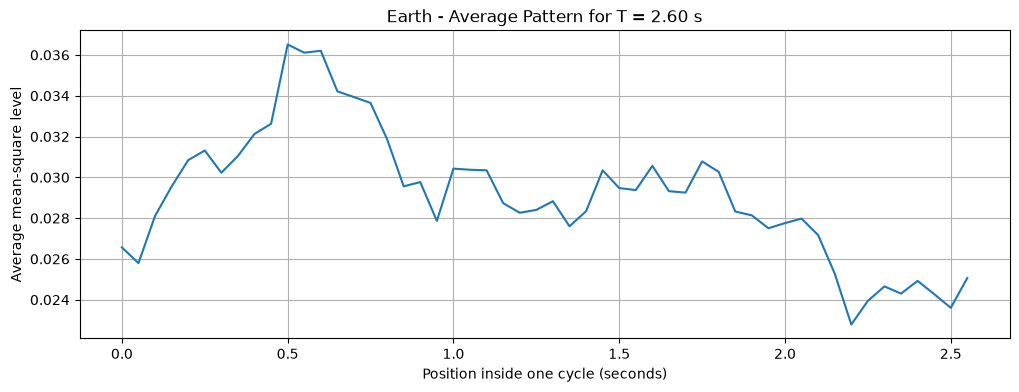

In [11]:
# Use the strongest detected candidate period
best_period = lag_times[top_candidates[0]]

# Convert the period from seconds to analysis windows
period_bins = int(round(best_period / window_seconds))

# Keep only complete cycles
usable_values = (len(local_energy) // period_bins) * period_bins
energy_for_cycles = local_energy[:usable_values]

# Each row represents one cycle
cycle_matrix = energy_for_cycles.reshape(-1, period_bins)

# Average all cycles
mean_cycle = np.mean(cycle_matrix, axis=0)

phase_time = np.arange(period_bins) * window_seconds

plt.figure(figsize=(12, 4))
plt.plot(phase_time, mean_cycle)

plt.xlabel("Position inside one cycle (seconds)")
plt.ylabel("Average mean-square level")
plt.title(f"Earth - Average Pattern for T = {best_period:.2f} s")
plt.grid()

plt.show()

In [12]:
# Strongest repeated position inside the cycle
best_phase_index = np.argmax(mean_cycle)
best_phase = phase_time[best_phase_index]

print(f"Detected period: {best_period:.2f} s")
print(f"Detected phase: {best_phase:.2f} s")

# Generate candidate moments throughout the song
candidate_times = np.arange(
    best_phase,
    t[-1],
    best_period
)

print("\nFirst candidate moments:")

for candidate in candidate_times[:20]:
    print(f"{candidate:.2f} s")

Detected period: 2.60 s
Detected phase: 0.50 s

First candidate moments:
0.50 s
3.10 s
5.70 s
8.30 s
10.90 s
13.50 s
16.10 s
18.70 s
21.30 s
23.90 s
26.50 s
29.10 s
31.70 s
34.30 s
36.90 s
39.50 s
42.10 s
44.70 s
47.30 s
49.90 s


### 2.8 Converting Candidate Times to Video Timecode

The previous step produces candidate positions in seconds. However, video editing is frame-based rather than purely time-based.

The reference video project uses a frame rate of:

$$
f_v = 24 \text{ fps}.
$$

Therefore, a candidate time \(t\) can be converted to a frame position using:

$$
F = \operatorname{round}(t \cdot f_v),
$$

where \(F\) is the total number of video frames from the beginning of the track.

The total frame count can then be expressed as standard video timecode:

$$
HH:MM:SS:FF
$$

where \(FF\) represents the frame number within the current second.

This conversion does not change the detected rhythmic pattern. It only translates the mathematical result into a format that can be checked directly against the manually edited timeline in DaVinci Resolve.

At this stage, the generated timecodes are **candidate edit points**, not confirmed correct cuts. Their usefulness must be evaluated by comparing them with the real manual edit decisions.

In [13]:
def seconds_to_timecode(seconds, fps=24, start_hour=1):
    total_frames = int(round(seconds * fps))

    frames = total_frames % fps
    total_seconds = total_frames // fps

    seconds_part = total_seconds % 60
    minutes = (total_seconds // 60) % 60
    hours = start_hour + total_seconds // 3600

    return f"{hours:02d}:{minutes:02d}:{seconds_part:02d}:{frames:02d}"


print("Candidate edit points:")

for candidate in candidate_times[:20]:
    print(
        f"{candidate:7.2f} s  ->  "
        f"{seconds_to_timecode(candidate)}"
    )

Candidate edit points:
   0.50 s  ->  01:00:00:12
   3.10 s  ->  01:00:03:02
   5.70 s  ->  01:00:05:17
   8.30 s  ->  01:00:08:07
  10.90 s  ->  01:00:10:22
  13.50 s  ->  01:00:13:12
  16.10 s  ->  01:00:16:02
  18.70 s  ->  01:00:18:17
  21.30 s  ->  01:00:21:07
  23.90 s  ->  01:00:23:22
  26.50 s  ->  01:00:26:12
  29.10 s  ->  01:00:29:02
  31.70 s  ->  01:00:31:17
  34.30 s  ->  01:00:34:07
  36.90 s  ->  01:00:36:22
  39.50 s  ->  01:00:39:12
  42.10 s  ->  01:00:42:02
  44.70 s  ->  01:00:44:17
  47.30 s  ->  01:00:47:07
  49.90 s  ->  01:00:49:22


### 2.9 Manual Validation in DaVinci Resolve

The generated candidate edit points were compared manually with the existing Earth video timeline in DaVinci Resolve.

The comparison showed that many detected points correspond closely to natural editing positions in the music.

Because the project uses a frame rate of 24 fps, one video frame represents:

$$
\frac{1}{24}\text{ s} \approx 41.67\text{ ms}.
$$

During manual validation, most differences between the detected candidate points and the existing edit decisions were approximately **1–2 frames**, corresponding to about **42–83 ms**.

In the representative comparisons shown below, several cuts match exactly or differ by only 1–3 frames (approximately 42–125 ms). Some editorial decisions intentionally deviate further from the detected timing when the visual content benefits from an earlier or later transition.:

$$
5 \cdot 41.67\text{ ms} \approx 208.35\text{ ms}.
$$

Several different cases were observed:

- some candidate points matched existing manual cuts almost exactly;
- some differed by only 1–2 frames;
- some manual cuts had intentionally been moved a few frames before or after the musical timing in order to reduce or increase the visual impact of the transition;
- some detected points suggested useful intermediate cuts in places where the original edit contained unusually long clips.

This indicates that the mathematical model should not be interpreted as an automatic replacement for editorial judgment.

Instead, it can provide a rhythmically consistent initial editing grid with sub-second precision. The editor can then make small frame-level adjustments according to the visual content and the desired artistic effect.

The purpose of the model is therefore not to predict one uniquely "correct" cut, but to identify mathematically supported candidate regions in which a cut is likely to feel natural.

For this track, the detected timing structure appears sufficiently accurate to reduce the amount of repeated trial-and-error normally required when choosing initial cut positions.

**The purpose of the model is therefore not to predict one uniquely "correct" cut, but to identify mathematically supported candidate regions in which a cut is likely to feel natural.**

#### Visual Validation Examples

The following screenshots show representative comparisons between the mathematically generated candidate times and the existing manual edit decisions in DaVinci Resolve.

The screenshots are not used as mathematical proof by themselves. They provide visual evidence for the manual validation process and illustrate the different types of agreement observed between the model and the existing edit.

<img src="figures/earth_validation_overview.png" width="900">

*Figure 1. Overview of multiple candidate points checked against the existing Earth timeline.*

<img src="figures/earth_validation_close_match.png" width="900">

*Figure 2. Example of a detected candidate point closely matching an existing manual cut.*

<img src="figures/earth_validation_shifted_cut.png" width="900">

*Figure 3. Example where the manual cut was intentionally shifted by a few frames relative to the detected timing.*

<img src="figures/earth_validation_alternative_cut.png" width="900">

*Figure 4. Example where the model suggests an additional rhythmically valid cut inside a longer manually edited shot.*

#### Representative Validation Results

The offset is measured relative to the mathematically detected candidate point.  
A negative value means that the manual edit was placed earlier, while a positive value means that it was placed later.

| Model candidate | Manual edit | Offset | Time difference | Interpretation |
|---|---|---:|---:|---|
| 01:00:05:17 | 01:00:05:15 | -2 frames | -83 ms | Very close; manual cut slightly anticipates the musical point |
| 01:00:08:07 | 01:00:08:04 | -3 frames | -125 ms | Manual cut intentionally occurs slightly earlier |
| 01:00:10:22 | 01:00:10:22 | 0 frames | 0 ms | Exact match |
| 01:00:18:17 | 01:00:18:22 | +5 frames | +208 ms | Manual edit delays the visual transition |
| 01:00:23:22 | 01:00:23:21 | -1 frame | -42 ms | Near-exact match |
| 01:00:29:02 | 01:00:29:02 | 0 frames | 0 ms | Exact match |
| 01:00:44:17 | 01:00:44:17 | 0 frames | 0 ms | Exact match |
| 01:00:49:22 | 01:00:49:23 | +1 frame | +42 ms | Near-exact match |
| 01:00:21:07 | — | — | — | Useful additional candidate inside a manually retained long shot |

### Reproducibility Check


The Earth analysis was tested from a clean kernel state using the complete original `earth.wav` source file included in the repository.

All Earth analysis cells executed sequentially from top to bottom without requiring manually pre-defined variables or external intermediate files.

### 2.10 Quantitative Validation of Timing Accuracy

The previous manual validation produced a set of measured frame offsets between mathematically detected candidate points and existing editorial decisions.

At 24 fps, one frame corresponds to:

$$
\frac{1}{24}\text{ s} \approx 41.67\text{ ms}.
$$

For each validated cut, the signed frame error is defined as:

$$
\Delta F = F_{\text{manual}} - F_{\text{model}}.
$$

A negative value means that the manual edit occurs earlier than the detected candidate, while a positive value means that it occurs later.

To evaluate the timing accuracy quantitatively, the following measures are calculated:

- mean signed error;
- mean absolute error;
- median absolute error;
- maximum absolute error;
- percentage of validated cuts within ±1, ±2, ±3, and ±5 frames.

The distribution of the measured frame errors is also visualized using a histogram.

In [14]:
# Measured frame offsets from the manual validation table
frame_errors = np.array([
    -2,
    -3,
     0,
     5,
    -1,
     0,
     0,
     1
])

fps = 24
frame_duration_ms = 1000 / fps

absolute_errors = np.abs(frame_errors)

mean_signed_error = np.mean(frame_errors)
mean_absolute_error = np.mean(absolute_errors)
median_absolute_error = np.median(absolute_errors)
max_absolute_error = np.max(absolute_errors)

print(f"Number of validated cuts: {len(frame_errors)}")
print(f"Mean signed error: {mean_signed_error:.2f} frames")
print(
    f"Mean absolute error: {mean_absolute_error:.2f} frames "
    f"({mean_absolute_error * frame_duration_ms:.1f} ms)"
)
print(
    f"Median absolute error: {median_absolute_error:.2f} frames "
    f"({median_absolute_error * frame_duration_ms:.1f} ms)"
)
print(
    f"Maximum absolute error: {max_absolute_error:.0f} frames "
    f"({max_absolute_error * frame_duration_ms:.1f} ms)"
)

for tolerance in [1, 2, 3, 5]:
    percentage = np.mean(absolute_errors <= tolerance) * 100
    print(
        f"Within ±{tolerance} frame(s): "
        f"{percentage:.1f}%"
    )

Number of validated cuts: 8
Mean signed error: 0.00 frames
Mean absolute error: 1.50 frames (62.5 ms)
Median absolute error: 1.00 frames (41.7 ms)
Maximum absolute error: 5 frames (208.3 ms)
Within ±1 frame(s): 62.5%
Within ±2 frame(s): 75.0%
Within ±3 frame(s): 87.5%
Within ±5 frame(s): 100.0%


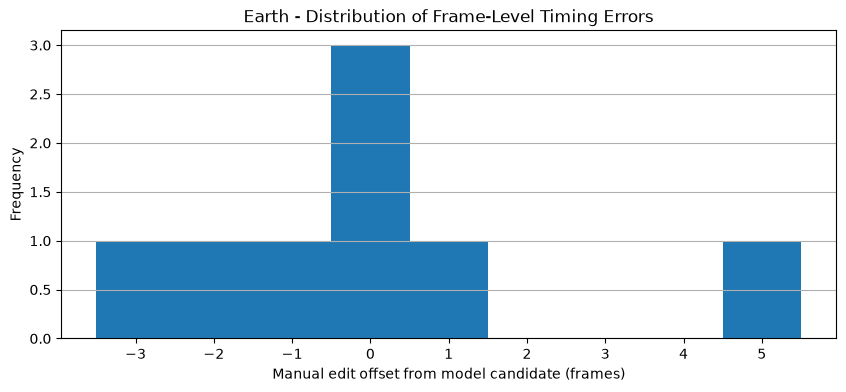

In [15]:
plt.figure(figsize=(10, 4))

bins = np.arange(frame_errors.min() - 0.5,
                 frame_errors.max() + 1.5,
                 1)

plt.hist(frame_errors, bins=bins)

plt.xlabel("Manual edit offset from model candidate (frames)")
plt.ylabel("Frequency")
plt.title("Earth - Distribution of Frame-Level Timing Errors")
plt.xticks(np.arange(frame_errors.min(), frame_errors.max() + 1))
plt.grid(axis="y")

plt.show()

#### Observation

The quantitative validation shows that the detected rhythmic grid is closely aligned with the manually selected edit points.

Across the 8 validated cuts:

- 
- the **mean signed error is 0.00 frames**, meaning that positive and negative offsets cancel out in these 8 comparisons;
- the **mean absolute error is 1.50 frames**, corresponding to approximately **62.5 ms**;
- the **median absolute error is 1 frame**, or approximately **41.7 ms**;
- **62.5%** of the validated cuts fall within ±1 frame;
- **75.0%** fall within ±2 frames;
- **87.5%** fall within ±3 frames;
- all validated cuts fall within ±5 frames.

The histogram also shows that most measured offsets are concentrated close to zero.

The sample is still small, so these values should be interpreted as evidence from the current Earth validation rather than as a general accuracy claim for the model.

However, the results support the practical use of the detected timing grid as a precise starting point for video editing, after which small frame-level adjustments can be made according to visual and artistic requirements.

## 3. Testing the Method on a Strongly Percussive Track

The Earth analysis showed a clear repeated timing structure and produced candidate edit points that closely matched the manually selected cuts.

The next step is to test whether the same mathematical method works on a contrasting track.

Unlike Earth, Fire contains stronger transients and more pronounced rhythmic attacks. The analysis is therefore repeated using the **same parameters and detection logic**, without tuning the method specifically for the new track.

This provides a first test of whether the approach can generalize beyond a single piece of music.

In [16]:
fire_path = Path("data/fire.wav")

if not fire_path.exists():
    raise FileNotFoundError(
        f"Audio file not found: {fire_path.resolve()}"
    )

sample_rate_fire, audio_fire = wavfile.read(fire_path)

print("Sample rate:", sample_rate_fire)
print("Shape:", audio_fire.shape)
print(
    "Duration:",
    len(audio_fire) / sample_rate_fire,
    "seconds"
)

Sample rate: 48000
Shape: (13016186, 2)
Duration: 271.1705416666667 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_67064\160407951.py:8: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate_fire, audio_fire = wavfile.read(fire_path)


### 3.1 Representing the Fire Audio Signal

The Fire recording is processed using the same representation used for Earth.

The stereo channels are combined into a mono signal, normalized to the interval \([-1,1]\), and represented as an amplitude function of time:

$$
x_{\mathrm{fire}}(t).
$$

Using the same mathematical representation allows the two tracks to be compared consistently.

In [17]:
# Combine stereo channels
audio_mono_fire = audio_fire.mean(axis=1).astype(np.float64)

# Normalize amplitude
x_fire = audio_mono_fire / np.max(np.abs(audio_mono_fire))

# Time axis
t_fire = np.arange(len(x_fire)) / sample_rate_fire

print(f"Number of samples: {len(x_fire)}")
print(f"Sampling rate: {sample_rate_fire} Hz")
print(f"Duration: {t_fire[-1]:.2f} seconds")

Number of samples: 13016186
Sampling rate: 48000 Hz
Duration: 271.17 seconds


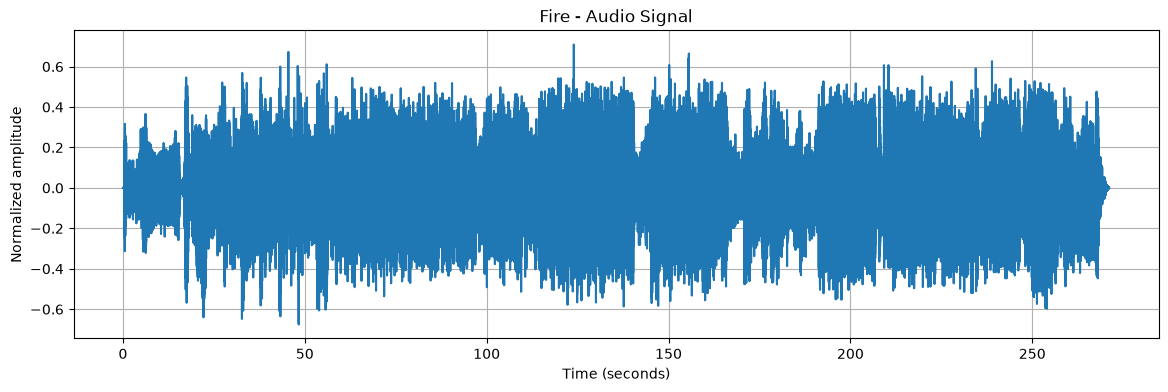

In [18]:
target_points = 100_000
step_fire = max(1, len(x_fire) // target_points)

plt.figure(figsize=(14, 4))

plt.plot(
    t_fire[::step_fire],
    x_fire[::step_fire]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Fire - Audio Signal")
plt.grid()

plt.show()

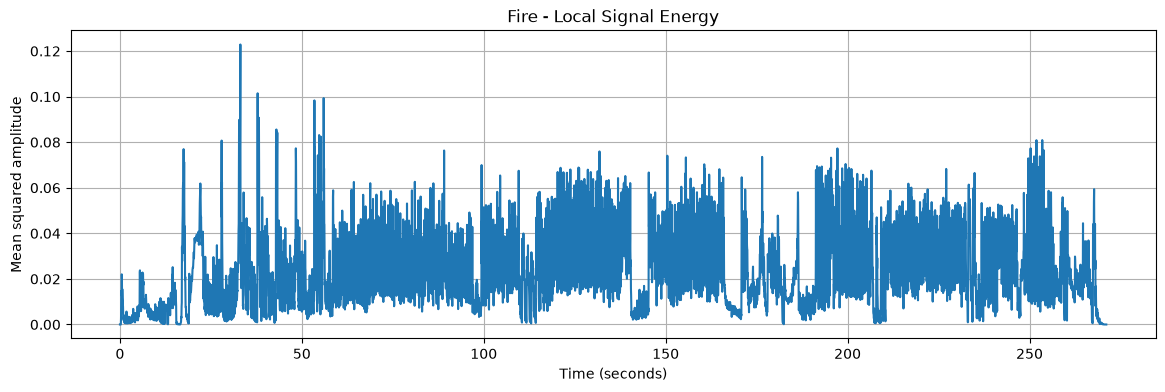

In [19]:
window_seconds = 0.05
window_size_fire = int(window_seconds * sample_rate_fire)

usable_samples_fire = (
    len(x_fire) // window_size_fire
) * window_size_fire

x_windows_fire = x_fire[:usable_samples_fire].reshape(
    -1,
    window_size_fire
)

local_energy_fire = np.mean(
    x_windows_fire ** 2,
    axis=1
)

energy_time_fire = (
    np.arange(len(local_energy_fire))
    * window_seconds
)

plt.figure(figsize=(14, 4))
plt.plot(
    energy_time_fire,
    local_energy_fire
)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean squared amplitude")
plt.title("Fire - Local Signal Energy")
plt.grid()

plt.show()

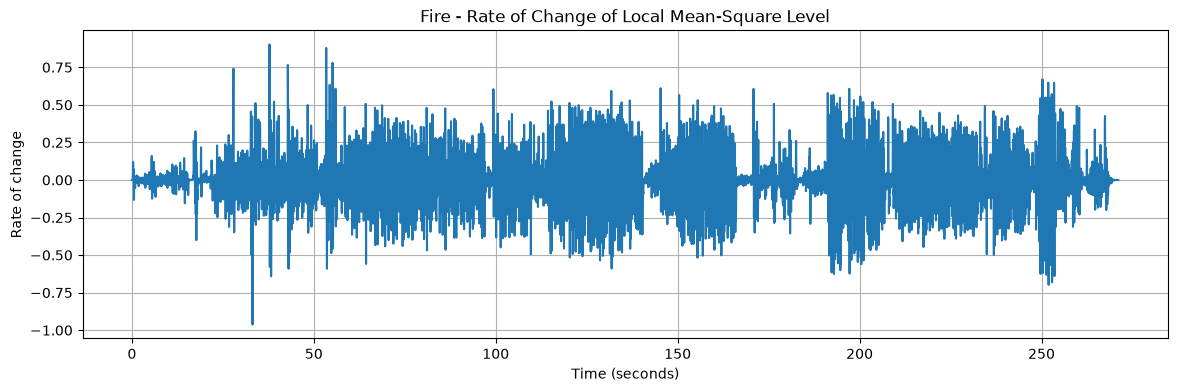

In [20]:
energy_change_fire = np.gradient(
    local_energy_fire,
    window_seconds
)

plt.figure(figsize=(14, 4))

plt.plot(
    energy_time_fire,
    energy_change_fire
)

plt.xlabel("Time (seconds)")
plt.ylabel("Rate of change")
plt.title(
    "Fire - Rate of Change of Local Mean-Square Level"
)
plt.grid()

plt.show()

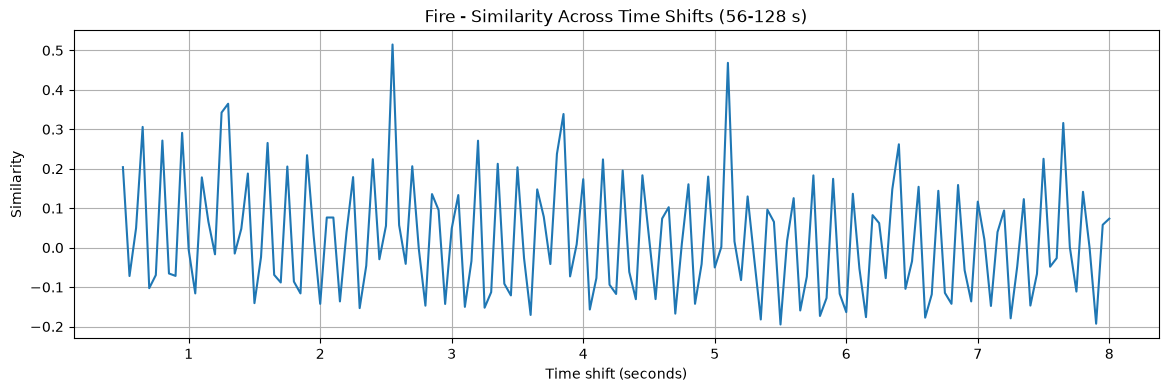

In [21]:

# Selected Fire section: 00:56 - 02:08
test_start_fire = 56.0
test_end_fire = 128.0

# Extract local energy for the selected section
start_bin_fire = int(round(test_start_fire / window_seconds))
end_bin_fire = int(round(test_end_fire / window_seconds))

test_energy_fire = local_energy_fire[
    start_bin_fire:end_bin_fire
]

# Remove the average level
energy_centered_fire = (
    test_energy_fire - np.mean(test_energy_fire)
)

# Use the same lag range as Earth
min_lag_seconds = 0.5
max_lag_seconds = 8.0

min_lag_fire = int(min_lag_seconds / window_seconds)
max_lag_fire = int(max_lag_seconds / window_seconds)

lags_fire = np.arange(
    min_lag_fire,
    max_lag_fire + 1
)

similarities_fire = []

for lag in lags_fire:
    a = energy_centered_fire[:-lag]
    b = energy_centered_fire[lag:]

    similarity = np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b)
    )

    similarities_fire.append(similarity)

lag_times_fire = lags_fire * window_seconds
similarities_fire = np.array(similarities_fire)

plt.figure(figsize=(14, 4))
plt.plot(lag_times_fire, similarities_fire)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Fire - Similarity Across Time Shifts (56-128 s)")
plt.grid()

plt.show()


In [22]:
candidate_min_seconds = 1.5

candidate_indices_fire = []

for i in range(
    1,
    len(similarities_fire) - 1
):
    is_local_maximum = (
        similarities_fire[i]
        > similarities_fire[i - 1]
        and
        similarities_fire[i]
        >= similarities_fire[i + 1]
    )

    is_long_enough = (
        lag_times_fire[i]
        >= candidate_min_seconds
    )

    if (
        is_local_maximum
        and is_long_enough
    ):
        candidate_indices_fire.append(i)

candidate_indices_fire = np.array(
    candidate_indices_fire
)

sorted_indices_fire = (
    candidate_indices_fire[
        np.argsort(
            similarities_fire[
                candidate_indices_fire
            ]
        )[::-1]
    ]
)

top_candidates_fire = (
    sorted_indices_fire[:8]
)

print("Top Fire candidate periods:")

for i in top_candidates_fire:
    print(
        f"{lag_times_fire[i]:.2f} s "
        f"(similarity = "
        f"{similarities_fire[i]:.3f})"
    )

Top Fire candidate periods:
2.55 s (similarity = 0.515)
5.10 s (similarity = 0.468)
3.85 s (similarity = 0.339)
7.65 s (similarity = 0.316)
3.20 s (similarity = 0.271)
1.60 s (similarity = 0.265)
6.40 s (similarity = 0.262)
1.90 s (similarity = 0.234)


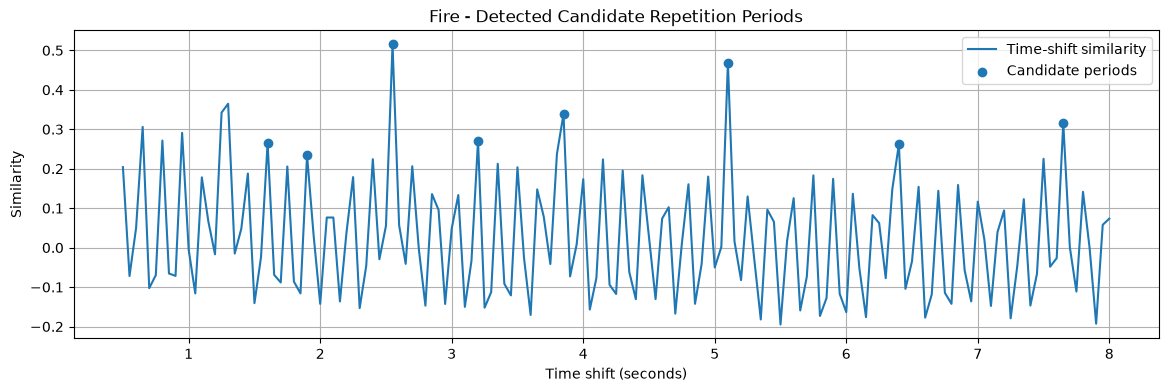

In [23]:
plt.figure(figsize=(14, 4))

plt.plot(
    lag_times_fire,
    similarities_fire,
    label="Time-shift similarity"
)

plt.scatter(
    lag_times_fire[top_candidates_fire],
    similarities_fire[top_candidates_fire],
    label="Candidate periods"
)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title(
    "Fire - Detected Candidate Repetition Periods"
)
plt.grid()
plt.legend()

plt.show()

### Observation

The same mathematical method developed for Earth was applied to a selected **72-second section of Fire (56–128 s)**, without changing the underlying detection algorithm.

The strongest detected repetition period was approximately **2.55 seconds**, demonstrating a recurring temporal structure in a second, musically contrasting composition.

The average-cycle analysis identified a phase offset of **0.05 seconds** relative to the beginning of the selected section.

These results confirm that the method can identify periodic structure in both a relatively calm orchestral composition (Earth) and a more aggressive, strongly percussive composition (Fire).

However, detecting the repetition period does not necessarily determine the exact musical onset suitable for a video cut.

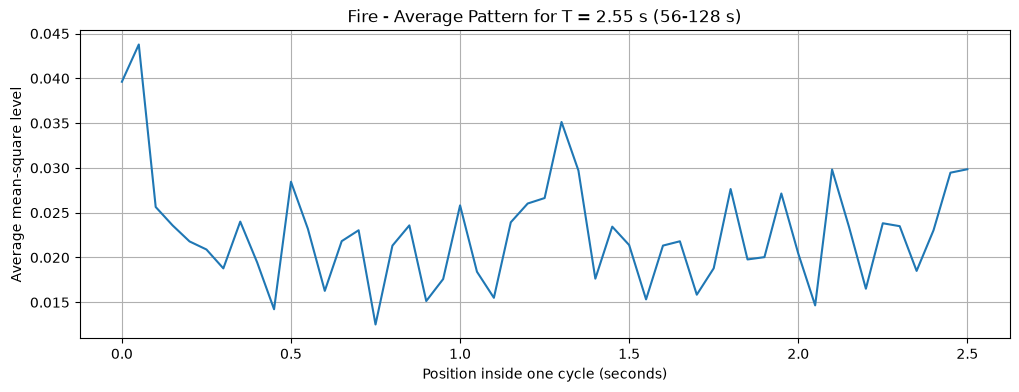

In [24]:

# Strongest detected Fire period
best_period_fire = lag_times_fire[top_candidates_fire[0]]

# Convert period into analysis windows
period_bins_fire = int(
    round(best_period_fire / window_seconds)
)

# Keep only complete cycles from the selected section
usable_values_fire = (
    len(test_energy_fire) // period_bins_fire
) * period_bins_fire

energy_for_cycles_fire = test_energy_fire[
    :usable_values_fire
]

# Divide the section into repeated cycles
cycle_matrix_fire = energy_for_cycles_fire.reshape(
    -1,
    period_bins_fire
)

# Calculate the average cycle
mean_cycle_fire = np.mean(
    cycle_matrix_fire,
    axis=0
)

phase_time_fire = (
    np.arange(period_bins_fire) * window_seconds
)

plt.figure(figsize=(12, 4))
plt.plot(phase_time_fire, mean_cycle_fire)

plt.xlabel("Position inside one cycle (seconds)")
plt.ylabel("Average mean-square level")
plt.title(
    f"Fire - Average Pattern for T = "
    f"{best_period_fire:.2f} s (56-128 s)"
)
plt.grid()

plt.show()


#### Observation and Method Limitation

The Fire signal reveals a repeated temporal structure, with prominent similarity peaks at approximately **2.55 s** and **5.10 s**.

However, manual testing in DaVinci Resolve showed that generating cuts at fixed intervals does not adequately follow the strong musical attacks. Some cuts occur between significant events, while rapid sequences of rhythmic hits remain undetected.

This suggests that global periodicity alone is insufficient for strongly percussive music.


The next step is to determine the phase of the detected period and generate candidate editing points for practical validation in DaVinci Resolve.

In [25]:

# Find the strongest position inside the average cycle
best_phase_index_fire = np.argmax(mean_cycle_fire)

best_phase_fire = phase_time_fire[
    best_phase_index_fire
]

print(f"Detected Fire period: {best_period_fire:.2f} s")
print(f"Detected Fire phase: {best_phase_fire:.2f} s")

# Generate absolute times within the selected section
candidate_times_fire = np.arange(
    test_start_fire + best_phase_fire,
    test_end_fire,
    best_period_fire
)

print("\nFire candidate edit points (56-128 s):")

for candidate in candidate_times_fire:
    print(
        f"{candidate:7.2f} s  ->  "
        f"{seconds_to_timecode(candidate)}"
    )


Detected Fire period: 2.55 s
Detected Fire phase: 0.05 s

Fire candidate edit points (56-128 s):
  56.05 s  ->  01:00:56:01
  58.60 s  ->  01:00:58:14
  61.15 s  ->  01:01:01:04
  63.70 s  ->  01:01:03:17
  66.25 s  ->  01:01:06:06
  68.80 s  ->  01:01:08:19
  71.35 s  ->  01:01:11:08
  73.90 s  ->  01:01:13:22
  76.45 s  ->  01:01:16:11
  79.00 s  ->  01:01:19:00
  81.55 s  ->  01:01:21:13
  84.10 s  ->  01:01:24:02
  86.65 s  ->  01:01:26:16
  89.20 s  ->  01:01:29:05
  91.75 s  ->  01:01:31:18
  94.30 s  ->  01:01:34:07
  96.85 s  ->  01:01:36:20
  99.40 s  ->  01:01:39:10
 101.95 s  ->  01:01:41:23
 104.50 s  ->  01:01:44:12
 107.05 s  ->  01:01:47:01
 109.60 s  ->  01:01:49:14
 112.15 s  ->  01:01:52:04
 114.70 s  ->  01:01:54:17
 117.25 s  ->  01:01:57:06
 119.80 s  ->  01:01:59:19
 122.35 s  ->  01:02:02:08
 124.90 s  ->  01:02:04:22
 127.45 s  ->  01:02:07:11



### Fire — Practical Validation in DaVinci Resolve

The detected editing points were tested against my manually edited timeline in DaVinci Resolve.

The mathematical model successfully identified the underlying rhythmic pulse of Fire, with a repetition period of approximately **2.55 seconds**.

However, the generated timing grid showed a consistent phase offset. After shifting the entire grid approximately **7–8 frames earlier** at 24 fps (about 0.29–0.33 seconds), the proposed cuts aligned closely with the musical rhythm.

This is a positive result for a second independent composition, using the same mathematical method as Earth.

The main limitation is that Fire contains strong percussive attacks, while the current model detects periodicity rather than individual musical attacks. Improving this distinction is a possible direction for future development, outside the scope of this project.

&nbsp;


The detected periodic structure is illustrated in the **"Fire - Detected Candidate Repetition Periods"** graph above, where the prominent similarity peaks occur at approximately **2.55 s** and **5.10 s**.

The following screenshots from DaVinci Resolve demonstrate the practical validation of the detected pulse against the manually edited timeline.


<img src="figures/fire_validation_overview.png" width="900">

*Figure 5. Overview of the Fire validation: the mathematically generated timing grid compared with the original manual edit in DaVinci Resolve.*

<img src="figures/fire_validation_alignment.png" width="900">

*Figure 6. Closer comparison of editing points after the manual phase adjustment of approximately 7–8 frames.*
